# Search Exercise 3 – Evolutionary algorithm: mutation vs. crossover

**Task.** Generate a random population of bit patterns, evaluate each pattern, keep the best 30 %, and create the remaining 70 % from them. Repeat until the best fitness stops improving. Then compare:
- **(a)** mutation only,
- **(b)** crossover only,
- **(c)** mutation and crossover.

All methods use 30 tests and are compared fairly, including run-times.

**Pattern size.** We use `N_BITS = 16` (a size that runs in reasonable time with the brute-force method of Exercise 1).

## Step 0 – Set-up

We import the libraries, fix a global random seed and define the constants used in all cells:
- `N_BITS`: length of the secret pattern,
- `SEEDS`: 30 fixed seeds, so every test can be reproduced.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)            # global seed for reproducibility
N_BITS = 16                  # pattern size used for Exercises 3 and 4 (see Exercise 1 results)
SEEDS = list(range(30))      # 30 fixed seeds -> 30 tests per result

## Step 1 – Fitness function

The feedback tells us how many bits of the guess match the secret pattern.

- **Fitness** = number of matching positions.
- Maximum fitness = `N_BITS` (the guess is exactly right).
- The fitness decreases as the guess differs more from the secret pattern.

We first check this with a few small examples.

In [2]:
def fitness(guess, target):
    """Number of positions where guess and target are equal (max = len(target))."""
    return int(np.sum(guess == target))

# Quick checks
t = np.array([1, 0, 1, 1])
assert fitness(t.copy(), t) == 4                       # exact match -> maximum
assert fitness(np.array([0, 1, 0, 0]), t) == 0         # all wrong
assert fitness(np.array([1, 0, 1, 0]), t) == 3         # one bit wrong
print("Fitness checks passed.")

Fitness checks passed.


## Step 2 – Random patterns and the two variation operators

- **`random_pattern`:** a random bit string of length `n`.
- **`mutate`:** flips one random bit (the same operator as hill climbing in Exercise 2).
- **`crossover`:** one-point crossover. A cut point is chosen; the child takes the left part from parent A and the right part from parent B. This combines good parts of two parents.

In [3]:
def random_pattern(n, rng):
    return rng.integers(0, 2, size=n)

def mutate(guess, rng):
    child = guess.copy()
    i = rng.integers(len(child))
    child[i] ^= 1                    # flip one bit
    return child

def crossover(parent_a, parent_b, rng):
    cut = rng.integers(1, len(parent_a))          # cut between position 1 and n-1
    return np.concatenate([parent_a[:cut], parent_b[cut:]])

# Quick checks
rng_test = np.random.default_rng(1)
a = np.zeros(8, dtype=int); b = np.ones(8, dtype=int)
c = crossover(a, b, rng_test)
assert len(c) == 8 and c[0] == 0 and c[-1] == 1  # left part from a, right part from b
m = mutate(a, rng_test)
assert np.sum(m != a) == 1                       # exactly one bit changed
print("Operator checks passed.")

Operator checks passed.


## Step 3 – Evolutionary loop

One run of the algorithm does the following in each generation:
1. Evaluate all 100 patterns with the fitness function.
2. Keep the best 30 % (the **elite**) unchanged.
3. Create the remaining 70 % with the chosen method:
   - `"mutation"`: mutate a random elite pattern,
   - `"crossover"`: cross two random elite patterns,
   - `"both"`: cross two elite patterns, then mutate the child with probability 0.5.
4. Stop when the best fitness has not improved for 20 generations (**stagnation**), or when the secret pattern is found.

We count the **evaluations** (how many fitness calls were made), because it is a fair measure of effort.

In [4]:
def run_ga(target, method, rng, pop_size=100, elite_frac=0.3, stagnation=20, max_gen=500):
    n = len(target)
    n_elite = int(elite_frac * pop_size)           # 30 patterns
    population = [random_pattern(n, rng) for _ in range(pop_size)]
    evaluations, best, stale, gen = 0, -1, 0, 0

    while True:
        scores = np.array([fitness(g, target) for g in population])
        evaluations += pop_size
        order = np.argsort(-scores, kind="stable")
        elite = [population[i] for i in order[:n_elite]]

        gen += 1
        if scores[order[0]] > best:
            best, stale = int(scores[order[0]]), 0
        else:
            stale += 1
        if best == n or stale >= stagnation or gen >= max_gen:
            break

        children = []
        while len(children) < pop_size - n_elite:
            if method == "mutation":
                child = mutate(elite[rng.integers(n_elite)], rng)
            elif method == "crossover":
                a, b = rng.choice(n_elite, 2, replace=False)
                child = crossover(elite[a], elite[b], rng)
            elif method == "both":
                a, b = rng.choice(n_elite, 2, replace=False)
                child = crossover(elite[a], elite[b], rng)
                if rng.random() < 0.5:
                    child = mutate(child, rng)
            else:
                raise ValueError(method)
            children.append(child)
        population = elite + children

    return {"best": best, "solved": best == n, "generations": gen, "evaluations": evaluations}

# Quick test on one seed
res = run_ga(random_pattern(N_BITS, np.random.default_rng(0)), "both", np.random.default_rng(0))
print(res)

{'best': 16, 'solved': True, 'generations': 1, 'evaluations': 100}


## Step 4 – Compare the three methods over 30 tests (a, b, c)

For every seed we create a new secret pattern and run each method. We record:
- whether the pattern was found (success rate),
- the number of evaluations,
- the run-time in seconds.

The same secret pattern is used for all three methods within one seed, so the comparison is fair.

In [5]:
methods = ["mutation", "crossover", "both"]
results = {m: {"evals": [], "time": [], "solved": [], "best": []} for m in methods}

for seed in SEEDS:
    target = random_pattern(N_BITS, np.random.default_rng(seed))
    for m in methods:
        t0 = time.perf_counter()
        r = run_ga(target, m, np.random.default_rng(1000 + seed))
        results[m]["time"].append(time.perf_counter() - t0)
        results[m]["evals"].append(r["evaluations"])
        results[m]["solved"].append(r["solved"])
        results[m]["best"].append(r["best"])

print(f"{'method':>10} | {'success':>7} | {'mean evals':>10} | {'sd evals':>8} | {'mean time [s]':>13}")
for m in methods:
    print(f"{m:>10} | {np.mean(results[m]['solved']):>7.2f} | {np.mean(results[m]['evals']):>10.0f} | "
          f"{np.std(results[m]['evals']):>8.0f} | {np.mean(results[m]['time']):>13.4f}")

    method | success | mean evals | sd evals | mean time [s]
  mutation |    1.00 |        657 |      141 |        0.0015
 crossover |    1.00 |        477 |      120 |        0.0019
      both |    1.00 |        490 |      114 |        0.0021


## Step 5 – Boxplots

Boxplots with whiskers show the spread of the 30 results for each method. Lower evaluations and time are better.

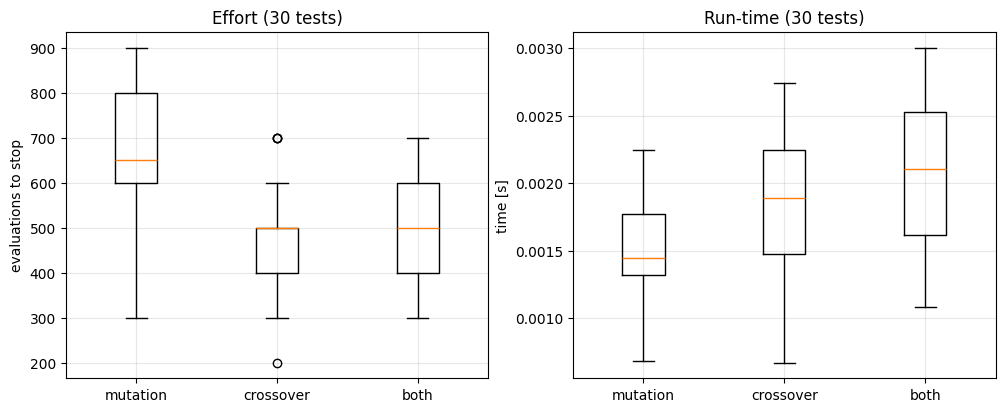

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot([results[m]["evals"] for m in methods])
ax[0].set_xticks([1, 2, 3], methods); ax[0].set_ylabel("evaluations to stop"); ax[0].set_title("Effort (30 tests)")
ax[0].grid(alpha=0.3)
ax[1].boxplot([results[m]["time"] for m in methods])
ax[1].set_xticks([1, 2, 3], methods); ax[1].set_ylabel("time [s]"); ax[1].set_title("Run-time (30 tests)")
ax[1].grid(alpha=0.3)
plt.show()

## Step 6 – Fair baseline from Exercises 1 and 2

To judge the evolutionary methods, we compare them with the two earlier methods on the same secret patterns:
- **Hill climbing (Exercise 2):** flip one bit, keep the change only if fitness improves, stop after 1000 mutations or when solved. All mutations are counted, including rejected ones.
- **Brute force (Exercise 1):** draw random patterns until the secret pattern appears.

In [7]:
def hill_climbing(target, rng, max_mutations=1000):
    n = len(target)
    current = random_pattern(n, rng)
    f = fitness(current, target)
    count = 0
    while count < max_mutations and f < n:
        candidate = mutate(current, rng)
        count += 1
        fc = fitness(candidate, target)
        if fc > f:                          # accept only improvements
            current, f = candidate, fc
    return {"mutations": count, "solved": f == n}

def brute_force(target, rng):
    attempts = 0
    while True:
        attempts += 1
        if np.array_equal(random_pattern(len(target), rng), target):
            return attempts

hc = {"mutations": [], "time": [], "solved": []}
bf = {"attempts": [], "time": []}
for seed in SEEDS:
    target = random_pattern(N_BITS, np.random.default_rng(seed))
    t0 = time.perf_counter(); r = hill_climbing(target, np.random.default_rng(2000 + seed))
    hc["time"].append(time.perf_counter() - t0); hc["mutations"].append(r["mutations"]); hc["solved"].append(r["solved"])
    t0 = time.perf_counter(); a = brute_force(target, np.random.default_rng(3000 + seed))
    bf["time"].append(time.perf_counter() - t0); bf["attempts"].append(a)

print(f"Hill climbing: success {np.mean(hc['solved']):.2f}, mean mutations {np.mean(hc['mutations']):.1f}, mean time {np.mean(hc['time']):.4f} s")
print(f"Brute force  : mean attempts {np.mean(bf['attempts']):.0f}, mean time {np.mean(bf['time']):.4f} s")

Hill climbing: success 1.00, mean mutations 41.4, mean time 0.0001 s
Brute force  : mean attempts 62281, mean time 0.1729 s


## Step 7 – Comparison table (all methods)

We now show the evolutionary methods next to the baselines. Evaluations and attempts are different units, so the table gives the effort in each method's own unit and the run-time, which is comparable.

In [8]:
print(f"{'method':>22} | {'success':>7} | {'effort (mean)':>13} | {'time [s]':>9}")
print(f"{'brute force (Ex.1)':>22} | {'1.00':>7} | {np.mean(bf['attempts']):>10.0f} att. | {np.mean(bf['time']):>9.4f}")
print(f"{'hill climbing (Ex.2)':>22} | {np.mean(hc['solved']):>7.2f} | {np.mean(hc['mutations']):>10.0f} mut. | {np.mean(hc['time']):>9.4f}")
for m in methods:
    print(f"{'GA ' + m:>22} | {np.mean(results[m]['solved']):>7.2f} | {np.mean(results[m]['evals']):>10.0f} eval. | {np.mean(results[m]['time']):>9.4f}")

                method | success | effort (mean) |  time [s]
    brute force (Ex.1) |    1.00 |      62281 att. |    0.1729
  hill climbing (Ex.2) |    1.00 |         41 mut. |    0.0001
           GA mutation |    1.00 |        657 eval. |    0.0015
          GA crossover |    1.00 |        477 eval. |    0.0019
               GA both |    1.00 |        490 eval. |    0.0021


## Step 8 – Discussion

**Which method is best here?**
- Brute force needs on average about $$2^{n}$$ attempts (here about 62 000 for 16 bits), which grows exponentially with the pattern length.
- Hill climbing is cheap, because each step is a single flip, but it can get stuck (see Exercise 2, question c).
- The evolutionary methods keep a population, so they search several places at the same time.

**Mutation vs. crossover:**
- **Mutation only** explores by small random changes. It is robust, but each step is small.
- **Crossover only** can combine good parts of different patterns. However, when all patterns in the population become similar, crossover can produce nothing new, and the search stagnates early.
- **Both** keeps some of the new combinations of crossover and adds small changes, which usually helps.

**Caveat:** The results depend on the seeds, the population size, the elite fraction and the stagnation limit. We used the values given in the exercise, and the results should be read as a comparison, not as a general law.

## Footer

In [9]:
import os, platform
from datetime import datetime
print("-----------------------------------")
print(platform.system(), "|", platform.release())
print("Datetime:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python Version:", platform.python_version())
print("-----------------------------------")

-----------------------------------
Darwin | 27.2.0
Datetime: 2026-11-11 14:40:38
Python Version: 3.10.20
-----------------------------------
